# 03 | Forecast risk and explain the exceptions

Use the same portfolio, one-day horizon and 99% confidence level for all five models. A forecast dated \(t\) is made at the preceding NYSE close. Express VaR as a positive USD loss threshold and count an exception only if the realized loss strictly exceeds it.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.stats import norm

private = Path("data/private")
results = Path("results")
figures = Path("figures")
figures.mkdir(exist_ok=True)
portfolio = pd.read_csv(private / "portfolio.csv", index_col="date", parse_dates=True)
returns = portfolio["portfolio_return"]
nav = portfolio["portfolio_value_usd"]
models = {
    "hs": "Historical Simulation",
    "ewhs": "Exponentially Weighted HS",
    "ewma": "Gaussian EWMA",
    "garch": "Gaussian GARCH(1,1)",
    "vfhs": "Volatility-Filtered HS",
}
tail = 0.01
normal_cutoff = norm.ppf(1 - tail)

## Estimate Gaussian GARCH(1,1) once on 2007

With zero mean, \(h_t=\omega+\alpha r_{t-1}^2+\beta h_{t-1}\). If the previous innovation is unobserved, use its conditional expected square \(h_{t-1}\). Keep the full session index so gaps advance the state without inserting zero returns. The Gaussian likelihood includes observed returns only and uses the first 21 valid 2007 returns to seed variance. Since all of 2007 is available at the start of 2008, this seed is known before any scored day. Estimate in percentage-return units for numerical conditioning, then convert \(\omega\) and the seed variance back to squared decimals by dividing by \(100^2\).

In [2]:
def garch_variances(values, omega, alpha, beta, starting_variance):
    variances = np.empty(len(values))
    variance = starting_variance
    for day, value in enumerate(values):
        variances[day] = variance
        shock_squared = value ** 2 if np.isfinite(value) else variance
        variance = omega + alpha * shock_squared + beta * variance
    return variances

def fit_garch(initialization_returns):
    percent_returns = initialization_returns.to_numpy() * 100
    observed = np.isfinite(percent_returns)
    starting_variance = np.var(percent_returns[observed][:21], ddof=1)

    def negative_log_likelihood(parameters):
        omega, alpha, beta = parameters
        variance = garch_variances(percent_returns, omega, alpha, beta, starting_variance)[observed]
        squared_returns = percent_returns[observed] ** 2
        return 0.5 * np.sum(np.log(variance) + squared_returns / variance)

    fit = minimize(
        negative_log_likelihood,
        x0=[0.05 * starting_variance, 0.05, 0.90],
        method="SLSQP",
        bounds=[(1e-8, None), (0.0, 0.9999), (0.0, 0.9999)],
        constraints={"type": "ineq", "fun": lambda p: 0.9999 - p[1] - p[2]},
        options={"ftol": 1e-10, "maxiter": 1_000},
    )
    assert fit.success and np.isfinite(fit.fun), fit.message
    omega, alpha, beta = fit.x
    assert omega > 0 and alpha >= 0 and beta >= 0 and alpha + beta < 1
    return omega / 100**2, alpha, beta, starting_variance / 100**2

garch_parameters = fit_garch(returns.loc["2007"])
garch_details = pd.DataFrame([garch_parameters], columns=["omega_decimal_squared", "alpha", "beta",
                                                          "seed_variance_decimal_squared"])
garch_details["persistence"] = garch_details["alpha"] + garch_details["beta"]
garch_details.to_csv(results / "garch_fit.csv", index=False)
display(garch_details)

,omega_decimal_squared,alpha,beta,seed_variance_decimal_squared,persistence
0,0.000004,0.074588,0.913045,0.000033,0.987633


## Build five forecasts using yesterday's information set

Historical simulation uses the linearly interpolated 1% quantile of all earlier valid daily portfolio returns. Exponentially weighted HS ranks those returns with weights proportional to \(0.995^{\text{session age}}\), then takes the first return whose cumulative weight reaches 1%.

Gaussian EWMA updates yesterday's conditional variance with yesterday's squared return using decay 0.96. An unobserved shock leaves the variance unchanged in expectation. GARCH uses the fixed coefficients from 2007 and the same time ordering.

Volatility-filtered HS divides each historical return by the sample standard deviation of the most recent 21 valid one-day returns **before** that observation. It estimates the 1% standardized shock and rescales it by the same trailing-volatility rule for the forecast date. A gap extends the calendar span of the 21-return window. A usable portfolio return always spans exactly one scheduled NYSE interval.

In [3]:
def one_day_var(portfolio_returns, portfolio_value, garch_fit):
    values = portfolio_returns.to_numpy()
    observed_returns = portfolio_returns.dropna()
    realized_volatility = observed_returns.rolling(21).std()
    prior_volatility = realized_volatility.reindex(portfolio_returns.index).ffill().shift()
    shocks = (portfolio_returns / prior_volatility.where(prior_volatility.gt(0))).to_numpy()

    garch_variance = garch_variances(values, *garch_fit)
    assert np.isfinite(garch_variance).all() and (garch_variance > 0).all()

    ewma_variance = np.nan
    forecasts = pd.DataFrame(index=portfolio_returns.index, columns=list(models), dtype=float)
    previous_value = portfolio_value.shift()
    for day in range(1, len(values)):
        history = values[:day]
        valid = np.isfinite(history)
        history = history[valid]

        if not np.isfinite(ewma_variance) and len(history) >= 21:
            ewma_variance = np.var(history[-21:], ddof=1)
        elif np.isfinite(values[day - 1]):
            ewma_variance = 0.96 * ewma_variance + 0.04 * values[day - 1] ** 2

        if len(history) < 21 or pd.isna(previous_value.iloc[day]):
            continue

        historical_cutoff = np.quantile(history, tail)
        order = np.argsort(history)
        ages = (day - 1 - np.flatnonzero(valid))[order]
        weights = 0.995 ** ages
        weighted_cdf = np.cumsum(weights) / weights.sum()
        weighted_cutoff = history[order][np.searchsorted(weighted_cdf, tail)]

        filtered_history = shocks[:day][np.isfinite(shocks[:day])]
        filtered_var = np.nan
        if len(filtered_history) >= 21:
            filtered_var = -np.quantile(filtered_history, tail) * prior_volatility.iloc[day]

        thresholds = np.array([
            -historical_cutoff,
            -weighted_cutoff,
            normal_cutoff * np.sqrt(ewma_variance),
            normal_cutoff * np.sqrt(garch_variance[day]),
            filtered_var,
        ])
        forecasts.iloc[day] = np.maximum(thresholds, 0) * previous_value.iloc[day]
    return forecasts

forecast = one_day_var(returns, nav, garch_parameters)
display(forecast.loc["2008"].head().round(2))

,hs,ewhs,ewma,garch,vfhs
date,,,,,
2008-01-02,2892.70,3043.46,3324.22,2935.88,3848.22
2008-01-03,2843.65,2993.18,3250.19,2877.88,3218.01
2008-01-04,2833.02,2983.32,3175.91,2763.92,3206.73
2008-01-07,2784.85,2933.90,3107.64,2718.94,2845.07
2008-01-08,2781.62,2931.80,3042.76,2615.77,2827.24


## Check forecast timing

Change the size and sign of observed returns from November 2008 onward and rebuild the forecasts. A forecast for the first changed date was made at the preceding close and must still match. Refit GARCH as part of the check using the same 2007-only slice. Hold the USD valuation scale fixed to isolate the risk-model inputs.

In [4]:
first_changed_date = returns.loc["2008-11":].first_valid_index()
changed_returns = returns.copy()
changed_returns.loc[first_changed_date:] *= -2
changed_fit = fit_garch(changed_returns.loc["2007"])
changed_forecast = one_day_var(changed_returns, nav, changed_fit)
pd.testing.assert_frame_equal(forecast.loc[:first_changed_date], changed_forecast.loc[:first_changed_date])
assert not forecast.loc[first_changed_date:].equals(changed_forecast.loc[first_changed_date:])

first_test_date = forecast.loc["2008"].dropna().index[0]
first_test_position = returns.index.get_loc(first_test_date)
first_test_history = returns.iloc[:first_test_position].dropna()
np.testing.assert_allclose(
    forecast.at[first_test_date, "hs"],
    -first_test_history.quantile(tail) * nav.shift().loc[first_test_date],
)
print(f"Forecasts through {first_changed_date.date()} are unchanged by later return edits.")

Forecasts through 2008-11-03 are unchanged by later return edits.


## Score all five models on the same 2008 dates

The realized loss is minus the portfolio P&L. An excess is the realized loss minus VaR on an exception day. Quantile loss charges 99 cents per dollar of undershoot and 1 cent per dollar of overshoot. It compares calibration and the size of the thresholds on the same dates. Smaller is better.

In [5]:
loss = (-portfolio["portfolio_pnl_usd"]).rename("loss_usd")
scoring_inputs = forecast.join(loss).loc["2008"]
test = scoring_inputs.dropna()
expected_dates = returns.loc["2008"].dropna().index
assert test.index.equals(expected_dates)
assert len(test) > 200 and test[list(models)].gt(0).all().all()

thresholds = test[list(models)]
excess = thresholds.rsub(test["loss_usd"], axis=0)
exceptions = excess.gt(0)
breaches = excess.where(exceptions)
quantile_loss = excess.clip(lower=0) * (1 - tail) - excess.clip(upper=0) * tail
summary = pd.DataFrame(
    {
        "model": pd.Series(models),
        "days": len(test),
        "expected_exceptions": len(test) * tail,
        "exceptions": exceptions.sum(),
        "exception_rate": exceptions.mean(),
        "mean_var_usd": thresholds.mean(),
        "mean_excess_usd": breaches.mean(),
        "max_excess_usd": breaches.max(),
        "mean_quantile_loss_usd": quantile_loss.mean(),
    }
).rename_axis("model_code")
summary.to_csv(results / "model_summary.csv", na_rep="N/A")
display(summary.round(3))

daily = test.rename(columns={code: f"{code}_var_usd" for code in models})
as_of = pd.Series(portfolio.index, index=portfolio.index).shift()
daily.insert(0, "forecast_as_of", as_of.loc[test.index])
daily.insert(1, "prior_value_usd", nav.shift().loc[test.index])
for code in models:
    daily[f"{code}_exception"] = exceptions[code]
    daily[f"{code}_excess_usd"] = breaches[code]
assert (daily["forecast_as_of"] < daily.index).all()
daily.to_csv(results / "daily_backtest.csv", na_rep="N/A", float_format="%.10g")

,model,days,expected_exceptions,exceptions,exception_rate,mean_var_usd,mean_excess_usd,max_excess_usd,mean_quantile_loss_usd
model_code,,,,,,,,,
hs,Historical Simulation,247,2.47,25,0.101,2824.306,1249.135,6518.226,152.569
ewhs,Exponentially Weighted HS,247,2.47,14,0.057,3612.701,1210.320,6143.750,102.623
ewma,Gaussian EWMA,247,2.47,3,0.012,4732.683,1909.382,4384.448,68.413
garch,"Gaussian GARCH(1,1)",247,2.47,6,0.024,4674.559,1197.570,4987.729,73.732
vfhs,Volatility-Filtered HS,247,2.47,6,0.024,5817.817,897.992,4286.909,77.887


## See when exceptions cluster

Count exceptions by calendar quarter and show any date with at least one breach. Consecutive breaches are counted only across adjacent NYSE sessions, including NYSE sessions excluded from scoring in the calendar.

In [6]:
quarterly = exceptions.groupby(exceptions.index.to_period("Q")).sum()
quarterly.to_csv(results / "quarterly_exceptions.csv", index_label="quarter")
full_calendar_flags = exceptions.reindex(scoring_inputs.index, fill_value=False)
consecutive = (full_calendar_flags & full_calendar_flags.shift(fill_value=False)).sum()
display(quarterly)
display(consecutive.rename("adjacent_exception_pairs").to_frame())

any_exception = daily.loc[exceptions.any(axis=1)].copy()
any_exception["models_breached"] = exceptions.loc[any_exception.index].sum(axis=1)
any_exception.to_csv(results / "exception_days.csv", na_rep="N/A", float_format="%.10g")
display(any_exception[["forecast_as_of", "loss_usd", "models_breached"]].round(2))

,hs,ewhs,ewma,garch,vfhs
date,,,,,
2008Q1,5,2,0,1,2
2008Q2,2,2,1,2,2
2008Q3,10,7,1,1,1
2008Q4,8,3,1,2,1


,adjacent_exception_pairs
hs,3
ewhs,0
ewma,0
garch,0
vfhs,0


,forecast_as_of,loss_usd,models_breached
date,,,
2008-01-15,2008-01-14,2865.17,3
2008-01-17,2008-01-16,2791.98,2
2008-02-05,2008-02-04,3665.33,2
2008-02-29,2008-02-28,2875.98,1
2008-03-14,2008-03-13,2622.84,2
2008-06-06,2008-06-05,2654.78,4
2008-06-26,2008-06-25,2833.44,5
2008-07-14,2008-07-11,2051.39,1
2008-07-15,2008-07-14,2202.19,2


## Attribute the three largest observed losses

Choose the dates by realized portfolio loss alone. For each bank, its prior-close USD position value multiplied by its USD price change equals its contribution. Keep positive contributions visible and flag up to three largest negative contributions.

In [7]:
prior_positions = pd.read_csv(private / "bank_values.csv", index_col="date", parse_dates=True).shift()
bank_pnl = pd.read_csv(private / "bank_pnl.csv", index_col="date", parse_dates=True)
bank_returns = pd.read_csv(private / "bank_returns.csv", index_col="date", parse_dates=True)
worst_dates = loss.loc["2008"].nlargest(3).index
assert worst_dates.isin(test.index).all()
worst_days = daily.loc[worst_dates]
worst_days.to_csv(results / "worst_days.csv", na_rep="N/A", float_format="%.10g")
display(worst_days[["forecast_as_of", "loss_usd", *[f"{code}_var_usd" for code in models]]].round(2))

attribution = pd.concat(
    {
        "prior_position_usd": prior_positions.loc[worst_dates].stack(),
        "usd_price_return": bank_returns.loc[worst_dates].stack(),
        "pnl_usd": bank_pnl.loc[worst_dates].stack(),
    },
    axis=1,
).rename_axis(index=["date", "bank_code"])
attribution["loss_rank"] = (
    attribution["pnl_usd"].where(attribution["pnl_usd"] < 0).groupby(level="date").rank(method="first")
)
np.testing.assert_allclose(attribution["pnl_usd"],
                           attribution["prior_position_usd"] * attribution["usd_price_return"],
                           atol=1e-8)
np.testing.assert_allclose(
    attribution["pnl_usd"].groupby(level="date").sum().reindex(worst_dates), -loss.loc[worst_dates],
    atol=1e-8,
)
attribution.to_csv(results / "worst_day_attribution.csv", na_rep="N/A", float_format="%.10g")
display(attribution.round({"prior_position_usd": 2, "usd_price_return": 4, "pnl_usd": 2}))

,forecast_as_of,loss_usd,hs_var_usd,ewhs_var_usd,ewma_var_usd,garch_var_usd,vfhs_var_usd
date,,,,,,,
2008-10-07,2008-10-06,10168.19,3649.97,7918.06,9055.45,9481.49,13463.37
2008-09-15,2008-09-12,9663.59,3270.44,3519.84,5279.14,4675.86,5376.68
2008-09-29,2008-09-26,9010.07,3813.21,4811.23,9522.65,10287.99,13187.92


prior_position_usd  usd_price_return  pnl_usd  loss_rank
date       bank_code                                                          
2008-10-07 GS                     617.78           -0.0726   -44.84        8.0
           UBS                    317.27           -0.1073   -34.04        9.0
           JPM                    915.33           -0.1064   -97.36        4.0
           C                     8548.19           -0.1298 -1109.64        2.0
           BCS                   1707.75           -0.2198  -375.35        3.0
           MS                     287.92           -0.2489   -71.67        6.0
           DB                     478.94           -0.1338   -64.06        7.0
           BAC                  32028.29           -0.2623 -8399.72        1.0
           BNP                   7742.36            0.0136   104.95        NaN
           CS                     660.82           -0.1157   -76.45        5.0
2008-09-15 GS                     768.28           -0.1213   -93.21        5.0
           UBS                    353.19           -0.1792   -63.28        7.0
           JPM                    856.46           -0.1013   -86.75        6.0
           C                     8818.23           -0.1514 -1335.50        2.0
           BCS                   1842.38           -0.1469  -270.72        4.0
           MS                     456.14           -0.1354   -61.75        8.0
           DB                     609.72           -0.0812   -49.50       10.0
           BAC                  33539.25           -0.2131 -7147.22        1.0
           BNP                   7637.40           -0.0660  -503.86        3.0
           CS                     661.67           -0.0782   -51.78        9.0
2008-09-29 GS                     687.48           -0.1253   -86.14        8.0
           UBS                    343.79           -0.2264   -77.82        9.0
           JPM                   1003.54           -0.1501  -150.61        5.0
           C                     9893.51           -0.1191 -1178.38        2.0
           BCS                   2181.89           -0.1616  -352.67        4.0
           MS                     303.23           -0.1519   -46.07       10.0
           DB                     610.02           -0.1739  -106.10        6.0
           BAC                  36481.64           -0.1757 -6411.62        1.0
           BNP                   8407.24           -0.0591  -496.67        3.0
           CS                     743.83           -0.1398  -103.98        7.0

## Plot value, forecast behavior and attribution

Plot gaps on the original NYSE session index. Use the same loss scale across the five VaR panels so threshold sizes and exceptions are directly comparable.

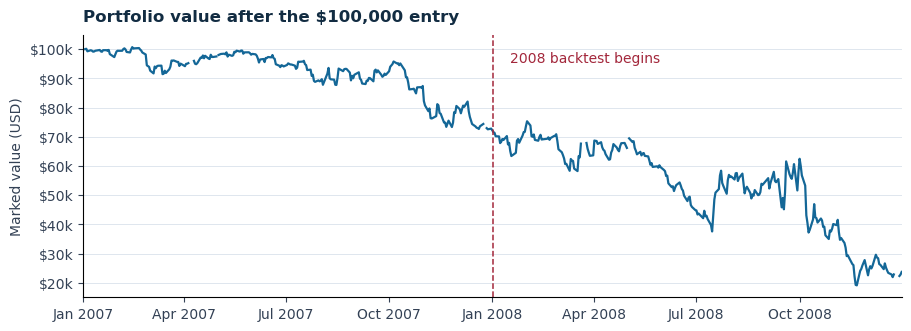

In [8]:
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.spines.top": False,
    "axes.spines.right": False, "axes.axisbelow": True, "axes.labelcolor": "#334155",
    "text.color": "#122c42", "xtick.color": "#334155", "ytick.color": "#334155",
    "grid.color": "#d9e2eb", "grid.linewidth": 0.6, "savefig.dpi": 200,
})
blue, red, teal, gray = "#146797", "#a3273b", "#11746d", "#64748b"

def dollars_thousands(value, _):
    return f"${value / 1_000:,.0f}k" if value >= 0 else f"−${abs(value) / 1_000:,.0f}k"

fig, ax = plt.subplots(figsize=(9, 3.2), layout="constrained")
ax.plot(nav.index, nav, color=blue, linewidth=1.6)
ax.axvline(first_test_date, color=red, linestyle="--", linewidth=1.1)
ax.set_title("Portfolio value after the $100,000 entry", loc="left", fontweight="bold", pad=10)
ax.text(first_test_date + pd.Timedelta(days=15), 0.94, "2008 backtest begins",
        transform=ax.get_xaxis_transform(), color=red, va="top")
ax.set_ylabel("Marked value (USD)")
ax.yaxis.set_major_formatter(FuncFormatter(dollars_thousands))
ax.set_xlim(pd.Timestamp("2007-01-01"), pd.Timestamp("2008-12-31"))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.grid(axis="y")
fig.savefig(figures / "portfolio_value.png", facecolor="white")
plt.show()

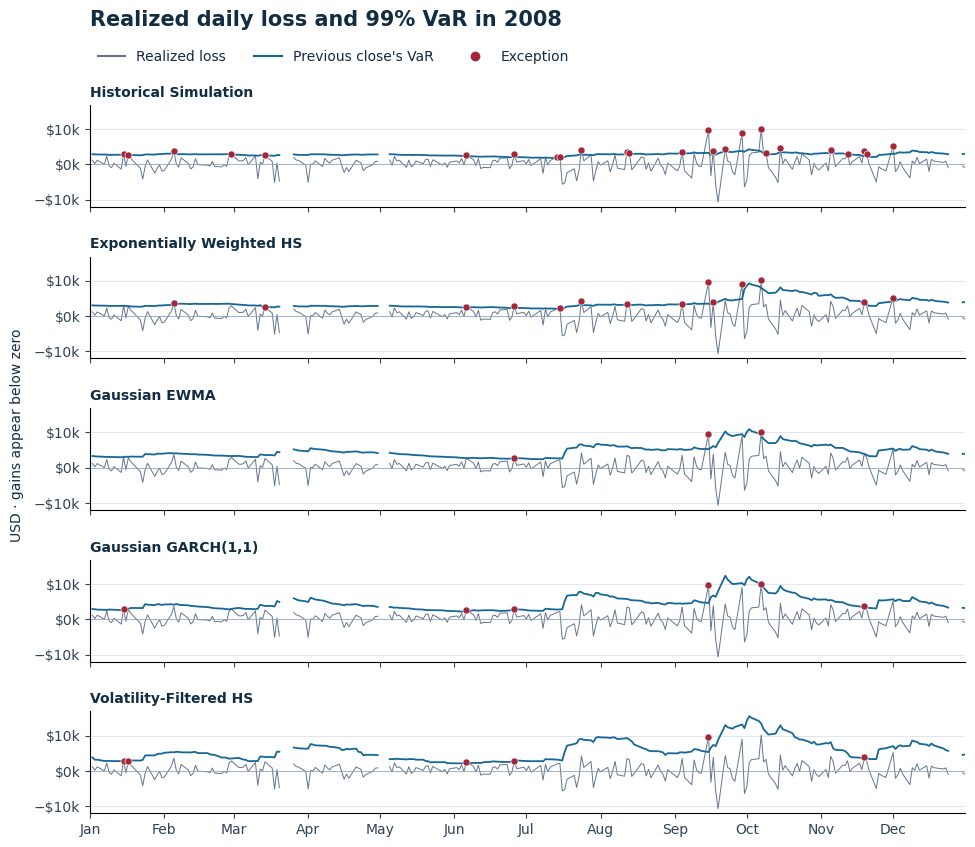

In [9]:
from matplotlib.lines import Line2D

fig, axes = plt.subplots(5, 1, figsize=(10, 8.8), sharex=True, sharey=True)
fig.subplots_adjust(top=0.875, bottom=0.07, left=0.105, right=0.98, hspace=0.49)
fig.suptitle("Realized daily loss and 99% VaR in 2008", x=0.105, y=0.983, ha="left",
             fontsize=15, fontweight="bold")
legend = [
    Line2D([], [], color=gray, label="Realized loss"),
    Line2D([], [], color=blue, label="Previous close's VaR"),
    Line2D([], [], color=red, label="Exception", marker="o", linestyle="none"),
]
fig.legend(handles=legend, ncol=3, loc="upper left", bbox_to_anchor=(0.1, 0.952), frameon=False)
for ax, (code, label) in zip(axes, models.items()):
    ax.set_title(label, loc="left", fontsize=10, fontweight="bold")
    ax.plot(scoring_inputs.index, loss.reindex(scoring_inputs.index), color=gray, linewidth=0.7)
    ax.plot(scoring_inputs.index, thresholds[code].reindex(scoring_inputs.index), color=blue, linewidth=1.3)
    mark = exceptions.index[exceptions[code]]
    ax.scatter(mark, loss.loc[mark], color=red, edgecolors="white", linewidth=0.45, s=26, zorder=4)
    ax.axhline(0, linewidth=0.55, color="#94a3b8")
    ax.grid(axis="y")
    ax.yaxis.set_major_formatter(FuncFormatter(dollars_thousands))
axes[-1].set_xlim(pd.Timestamp("2008-01-01"), pd.Timestamp("2008-12-31"))
axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
fig.supylabel("USD · gains appear below zero", x=0.025, fontsize=10)
fig.savefig(figures / "var_backtest.png", facecolor="white")
plt.show()

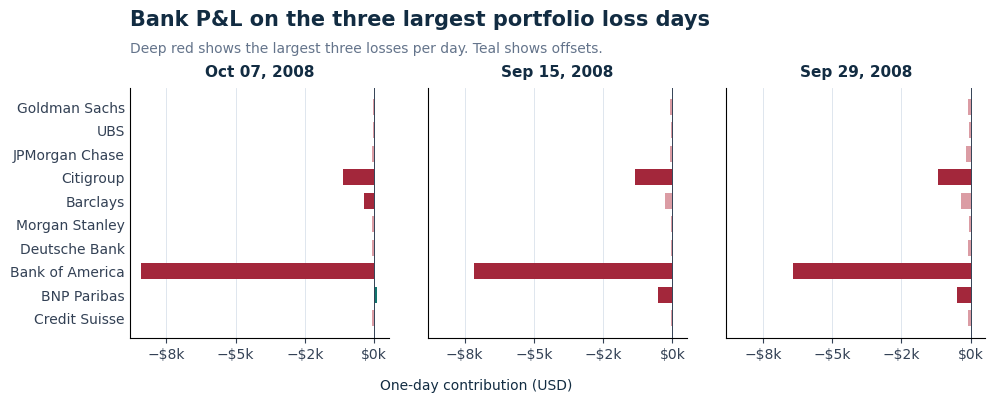

In [10]:
names = pd.read_csv(results / "data_coverage.csv", index_col="bank_code")["bank"]
fig, axes = plt.subplots(1, 3, figsize=(10.5, 4.1), sharex=True, sharey=True)
fig.subplots_adjust(top=0.78, bottom=0.17, left=0.17, right=0.985, wspace=0.15)
fig.suptitle("Bank P&L on the three largest portfolio loss days", x=0.17, y=0.97, ha="left",
             fontsize=15, fontweight="bold")
fig.text(0.17, 0.865, "Deep red shows the largest three losses per day. Teal shows offsets.",
         fontsize=10, color=gray)
for ax, date in zip(axes, worst_dates):
    detail = attribution.loc[date].reindex(names.index)
    colors = np.where(detail["pnl_usd"] > 0, teal, np.where(detail["loss_rank"] <= 3, red, "#db9ca4"))
    ax.barh(names, detail["pnl_usd"], color=colors, height=0.68)
    ax.axvline(0, color="#334155", linewidth=0.7)
    ax.set_title(date.strftime("%b %d, %Y"), fontsize=11, fontweight="bold", pad=8)
    ax.grid(axis="x")
    ax.xaxis.set_major_locator(plt.MaxNLocator(nbins=4))
    ax.xaxis.set_major_formatter(FuncFormatter(dollars_thousands))
    ax.tick_params(axis="y", length=0)
axes[0].invert_yaxis()
fig.supxlabel("One-day contribution (USD)", y=0.035, fontsize=10)
fig.savefig(figures / "worst_day_attribution.png", facecolor="white")
plt.show()